In [ ]:
import io
import sys
import zipfile
from glob import glob
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cartopy.io.shapereader as shpreader
from matplotlib.collections import LineCollection
from pyproj import Transformer

sys.path.append("../..")
from src.data import dataset_utils as du
from src.data import graph_utils as gu

ZARR_PATH = "/work/ka1176/shared_data/2025-wwm-emulator-schism/processed_RUN04b_JUWELS_wpile.zarr"
BOUNDARY_NODES_CSV = "../../src/data/node_selection/boundary_nodes.csv"
DATA_CRS = ccrs.UTM(32)  # SCHISM_hgrid_node_x/y are projected UTM zone 32N
LONLAT_TRANSFORMER = Transformer.from_crs("epsg:32632", "epsg:4326", always_xy=True)

ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")

node_x = ds_true["SCHISM_hgrid_node_x"].values
node_y = ds_true["SCHISM_hgrid_node_y"].values

print(f"node_x range: [{node_x.min():.2f}, {node_x.max():.2f}]")
print(f"node_y range: [{node_y.min():.2f}, {node_y.max():.2f}]")
print(f"Total nodes: {len(node_x)}, total time steps: {ds_true.sizes['time']}")

node_x range: [-170936.47, 588878.00]
node_y range: [5550339.00, 6211776.00]
Total nodes: 589428, total time steps: 8760


/tmp/ipykernel_3420006/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 20. This could degrade performance. Instead, consider rechunking after loading.
  ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")
/tmp/ipykernel_3420006/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dimension "nSCHISM_hgrid_edge" starting at index 1677719. This could degrade performance. Instead, consider rechunking after loading.
  ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")
/tmp/ipykernel_3420006/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along dimension "two" starting at index 1. This could degrade performance. Instead, consider rechunking after loading.
  ds_true = xr.open_dataset(ZARR_PATH, engine="zarr", chunks="auto")
/tmp/ipykernel_3420006/3658512320.py:28: UserWarning: The specified chunks separate the stored chunks along

In [ ]:
PAPER_WIDE = (7.1, 3.5)
PAPER_NARROW = (3.5, 3.5/1.6)

In [ ]:
import seaborn as sns
sns.set_context("paper")

## Study domain

/tmp/ipykernel_3420006/1793566450.py:67: DeprecationWarning: The 'shapely.vectorized.contains' function is deprecated and will be removed a future version. Use 'shapely.contains_xy' instead (available since shapely 2.0.0).
  inside_mask = contains(domain_polygon, lon2d, lat2d)


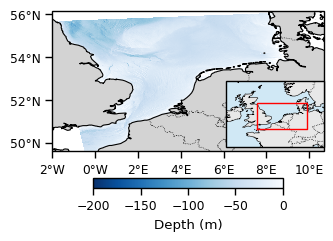

In [ ]:
"""
Fetch GEBCO_2020 bathymetry from NOAA's public ERDDAP server (griddap),
clipped to the study domain, with everything OUTSIDE the actual
(UTM-aligned, hence rotated in lon/lat) domain masked white.

Why ERDDAP/GEBCO instead of EMODnet WCS:
- Plain HTTP GET, no capabilities handshake, no server-side XML fault
  reports to parse, no per-request byte-size cap to negotiate.
- Subsetting happens server-side via bracket-index or lat/lon range
  syntax, so you only download what you need.

Requires: xarray, netCDF4, shapely, numpy, matplotlib, cartopy
    pip install netCDF4 shapely --break-system-packages
"""

import matplotlib.colors
from shapely.geometry import Polygon, Point
from shapely.vectorized import contains
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

# ---------------------------------------------------------------------
# 1) Build the ROTATED domain polygon in lon/lat (not just its bbox)
# ---------------------------------------------------------------------
pad_x = 0.02 * (node_x.max() - node_x.min())
pad_y = 0.02 * (node_y.max() - node_y.min())

xmin, xmax = node_x.min() - pad_x, node_x.max() + pad_x
ymin, ymax = node_y.min() - pad_y, node_y.max() + pad_y

corners_x_utm = [xmin, xmax, xmax, xmin]
corners_y_utm = [ymin, ymin, ymax, ymax]
corner_lons, corner_lats = LONLAT_TRANSFORMER.transform(corners_x_utm, corners_y_utm)
domain_polygon = Polygon(zip(corner_lons, corner_lats))

lon_min, lon_max = min(corner_lons), max(corner_lons)
lat_min, lat_max = min(corner_lats), max(corner_lats)

fetch_pad_lon = 0.02 * (lon_max - lon_min)
fetch_pad_lat = 0.02 * (lat_max - lat_min)
fetch_lon_min, fetch_lon_max = lon_min - fetch_pad_lon, lon_max + fetch_pad_lon
fetch_lat_min, fetch_lat_max = lat_min - fetch_pad_lat, lat_max + fetch_pad_lat

fetch_lon_max = 9.51

# ---------------------------------------------------------------------
# 2) Fetch GEBCO_2020 via ERDDAP griddap -- a plain HTTP GET, xarray
#    opens it directly over OPeNDAP without a manual download step.
# ---------------------------------------------------------------------
ERDDAP_URL = "https://coastwatch.pfeg.noaa.gov/erddap/griddap/GEBCO_2020"

# xarray can open the OPeNDAP endpoint lazily -- only the bbox slice
# below actually gets pulled over the wire.
ds = xr.open_dataset(ERDDAP_URL)  # lazy; needs 'pydap' or netCDF4 w/ opendap support

# GEBCO_2020 on this ERDDAP server exposes lat/lon as coordinate dims
# and an elevation variable (name may be 'elevation' -- check ds.data_vars
# if this KeyErrors).
da = ds["elevation"].sel(
    latitude=slice(fetch_lat_min, fetch_lat_max),
    longitude=slice(fetch_lon_min, fetch_lon_max),
).load()  # .load() triggers the actual (now-small) download

# ---------------------------------------------------------------------
# 3) Mask everything outside the ROTATED domain polygon
# ---------------------------------------------------------------------
lon2d, lat2d = np.meshgrid(da.longitude.values, da.latitude.values)
inside_mask = contains(domain_polygon, lon2d, lat2d)

depth = da.values  # GEBCO convention: negative = below sea level
sea_only = np.where(inside_mask & (depth < 0), depth, np.nan)

# ---------------------------------------------------------------------
# 4) Plot: colored bathymetry inside the domain, WHITE outside it
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(3.5, 3.5), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.set_facecolor("white")

norm = matplotlib.colors.Normalize(vmin=-200, vmax=0)
mesh = ax.pcolormesh(
    da.longitude.values,
    da.latitude.values,
    sea_only,
    transform=ccrs.PlateCarree(),
    cmap="Blues_r",
    norm=norm,
    shading="auto",
    zorder=1,
)

ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=2)
ax.coastlines(resolution="10m", linewidth=0.8, zorder=3)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5, zorder=3)

ax.set_xticks([-2, 0, 2, 4, 6, 8, 10], crs=ccrs.PlateCarree())
ax.set_yticks([50, 52, 54, 56], crs=ccrs.PlateCarree())
lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

dom_lons, dom_lats = domain_polygon.exterior.xy

cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.7, pad=0.1)
cbar.set_label("Depth (m)")


from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# --- inset: manual positioning instead of inset_locator ---
# [left, bottom, width, height] in FIGURE-relative coordinates (0-1)
axins = fig.add_axes([0.62, 0.27, 0.28, 0.28], projection=ccrs.PlateCarree())
axins.set_extent([-10, 15, 45, 62], crs=ccrs.PlateCarree())
axins.add_feature(cfeature.LAND, facecolor="#e8e8e8", zorder=1)
axins.add_feature(cfeature.OCEAN, facecolor="#d0e8f5", zorder=0)
axins.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5, zorder=3)
axins.coastlines(resolution="50m", linewidth=0.4, zorder=2)

# red box marking where the main map sits within this broader view
minx, miny, maxx, maxy = domain_polygon.bounds
axins.plot(
    [minx, maxx, maxx, minx, minx],
    [miny, miny, maxy, maxy, miny],
    color="red", linewidth=1.0, transform=ccrs.PlateCarree(), zorder=3,
)
axins.set_xticks([]); axins.set_yticks([])

#plt.tight_layout()
plt.savefig("paper_plots/study_domain_bathymetry_gebco.png", dpi=200, bbox_inches="tight")
plt.show()

## Data splits

Plot mean sig wave height across the study domain keeping the time axis and highlight data splits as observed in the experiment configuration swh_1h_mlp

In [ ]:
# domain-mean SWH per time step -- triggers a full reduction over ~590k nodes x 8760 steps
swh_domain_mean = ds_true["sigWaveHeight"].mean(dim="nSCHISM_hgrid_node").compute()

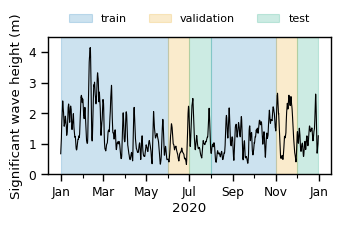

In [ ]:
import matplotlib.dates as mdates

# --- config -----------------------------------------------------------
SPLIT_DAYS = {
    "train": [[1, 152], [214, 305]],
    "validation": [[153, 182], [306, 335]],
    "test": [[183, 213], [336, 365]],
}
SPLIT_COLORS = {"train": "#0072B2", "validation": "#E69F00", "test": "#009E73"}
SMOOTH_HOURS = 48  # <-- configurable smoothing window, in hours

time_delta = ds_true.time.values[1] - ds_true.time.values[0]
samples_per_day = int(pd.Timedelta(days=1) / time_delta)
samples_per_hour = pd.Timedelta(hours=1) / time_delta



# --- smoothing ----------------------------------------------------------
smooth_window = max(1, round(SMOOTH_HOURS * samples_per_hour))
if smooth_window > 1:
    swh_plot = swh_domain_mean.rolling(time=smooth_window, center=True, min_periods=1).mean()
else:
    swh_plot = swh_domain_mean

fig, ax = plt.subplots(figsize=PAPER_NARROW)
swh_plot.plot(ax=ax, color="k", linewidth=0.8)

for split, ranges in SPLIT_DAYS.items():
    for start_day, end_day in ranges:
        start_idx = (start_day - 1) * samples_per_day
        end_idx = end_day * samples_per_day - 1
        ax.axvspan(
            ds_true.time.values[start_idx],
            ds_true.time.values[end_idx],
            color=SPLIT_COLORS[split],
            alpha=0.2,
            label=split,
        )

# de-duplicate legend labels (axvspan is called once per contiguous range per split)
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
ax.legend(
    by_label.values(), by_label.keys(),
    loc="lower center", bbox_to_anchor=(0.5, 1.02),
    ncol=3, frameon=False, fontsize=8,
)

# --- x-axis: tick every month, abbreviated label, no year ---------------
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_minor_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

#plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

ax.set_xlabel("")
ax.set_ylabel("Significant wave height (m)")

ax.set_ylim(0, 4.5)

fig.tight_layout()

# year label centered at the very bottom, below the month ticks
ax.text(0.5, -0.2, "2020", ha="center", va="top", transform=ax.transAxes)

plt.savefig("paper_plots/train_val_test_split.png", dpi=200, bbox_inches="tight")
plt.show()

## Subgraph partition

In [ ]:
nx = ds_true.SCHISM_hgrid_node_x
ny = ds_true.SCHISM_hgrid_node_y
ed = ds_true.SCHISM_hgrid_edge_nodes.isel(two=0)

In [ ]:
from lightning_utilities.core.rank_zero import rank_zero_only
rank_zero_only.rank = 0

In [ ]:
MAX_NODES_PARTITION = 500

# --- Build adjacency and partition the domain, exactly as predict_gcn.py does ---
adjacency = gu.build_adjacency(ds_true)

boundary_node_ids = du.load_node_indices(BOUNDARY_NODES_CSV)
ds_node_ids = ds_true.nSCHISM_hgrid_node.values
id_to_pos = {int(nid): pos for pos, nid in enumerate(ds_node_ids)}
boundary_positions = np.array([id_to_pos[int(nid)] for nid in boundary_node_ids if int(nid) in id_to_pos])
adjacency = gu.remove_boundary_nodes(adjacency, boundary_positions)

partitions = gu.partition_domain_disjoint(n_nodes=len(ds_node_ids), adjacency=adjacency, node_x = nx.values, node_y=ny.values, target_nodes=MAX_NODES_PARTITION)
print(f"{len(partitions)} sub-graphs covering the domain (max_nodes={MAX_NODES_PARTITION})")

[rank: 0] 229 single-node sub-graph(s) remain: those nodes have no neighbours left in the adjacency, so their prediction rests on their own features alone. Pass them via `excluded_nodes` if they should not be predicted at all.


1299 sub-graphs covering the domain (max_nodes=500)


In [ ]:
## how large are the partitions

In [ ]:
all_px = []
all_py = []

vnx = nx.values
vny = ny.values

for i, p in enumerate(partitions):
    px = vnx[p[1]]
    py = vny[p[1]]
    all_px.append(np.ptp(px))
    all_py.append(np.ptp(py))

In [ ]:
all_px = np.asarray(all_px)
all_py = np.asarray(all_py)

In [ ]:
np.median(all_px)

np.float32(468.34375)

In [ ]:
np.median(all_py)

np.float32(424.5)

In [ ]:
np.mean(all_px), np.mean(all_py)

(np.float32(5683.632), np.float32(5690.0317))

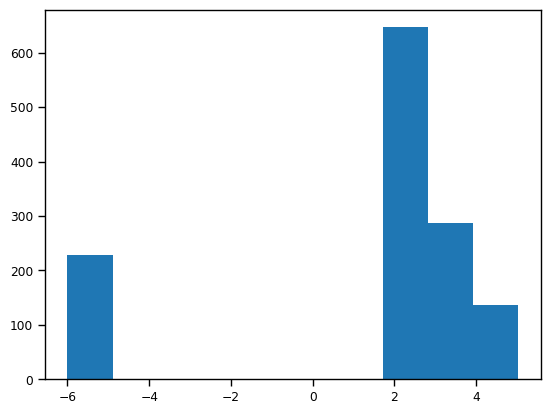

In [ ]:
plt.hist(np.log10(all_px + 1e-6));
#plt.xlim(0, 5);

Selected partitions to plot

In [ ]:
centers = np.array([p[0] for p in partitions])
center_x, center_y = LONLAT_TRANSFORMER.transform(node_x[centers], node_y[centers])

In [ ]:
center_latlon = np.stack([center_x, center_y]).T

In [ ]:
my_points = [
    (8.222, 54.917), # WES
    (7.868, 54.16),  # HEL
    (8.1105, 53.997), # ELB
    (7.15, 55.2), # FN3
]

In [ ]:
ips = []

for mp in my_points:
    distance = np.sqrt( (center_x - mp[0])**2 + (center_y - mp[1])**2 )
    print(center_latlon[np.argmin(distance)])

    ips.append(np.argmin(distance))

[ 8.08870553 55.00658574]
[ 7.85487001 54.13201193]
[ 8.08535776 54.0172456 ]
[ 7.16873231 54.94467832]


Overview where subgraphs are taken from

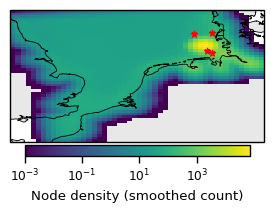

In [ ]:
from scipy.ndimage import gaussian_filter

fig, ax = plt.subplots(1, 1, subplot_kw={"projection": ccrs.PlateCarree()}, figsize=PAPER_NARROW)

ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.set_facecolor("white")

lon_all, lat_all = LONLAT_TRANSFORMER.transform(nx.values, ny.values)

nbins = 50  # coarser: aim for several nodes per cell, not 0-1
density, lon_edges, lat_edges = np.histogram2d(
    lon_all, lat_all, bins=nbins, range=[[lon_min, lon_max], [lat_min, lat_max]]
)

# smooth so it reads as a continuous field instead of blocky counting cells
density_smooth = gaussian_filter(density, sigma=1.0)
density_smooth = np.ma.masked_where(density_smooth <= 0, density_smooth)

mesh = ax.pcolormesh(
    lon_edges, lat_edges, density_smooth.T,
    cmap="viridis",
    norm=matplotlib.colors.LogNorm(vmin=max(density_smooth.min(), 1e-3), vmax=density_smooth.max()),
    transform=ccrs.PlateCarree(),
    zorder=1.5,
)

ax.add_feature(cfeature.LAND, facecolor="#e8e8e8", zorder=1)
ax.coastlines(resolution="10m", linewidth=0.6, zorder=3)

for ip in ips:
    nx_lon, nx_lat = LONLAT_TRANSFORMER.transform(
        nx.sel(nSCHISM_hgrid_node=partitions[ip][0]).values,
        ny.sel(nSCHISM_hgrid_node=partitions[ip][0]).values,
    )
    ax.scatter(nx_lon, nx_lat, color="red", marker="*", zorder=4)

cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.7, pad=0.02,)
cbar.set_label("Node density (smoothed count)")

fig.tight_layout()
plt.show()

/tmp/ipykernel_3420006/758058747.py:62: DeprecationWarning: The 'shapely.vectorized.contains' function is deprecated and will be removed a future version. Use 'shapely.contains_xy' instead (available since shapely 2.0.0).
  inside_mask = contains(domain_polygon, lon2d, lat2d)


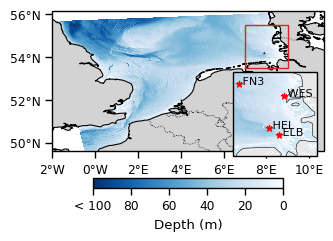

In [ ]:
"""
Fetch GEBCO_2020 bathymetry from NOAA's public ERDDAP server (griddap),
clipped to the study domain, with everything OUTSIDE the actual
(UTM-aligned, hence rotated in lon/lat) domain masked white.

Why ERDDAP/GEBCO instead of EMODnet WCS:
- Plain HTTP GET, no capabilities handshake, no server-side XML fault
  reports to parse, no per-request byte-size cap to negotiate.
- Subsetting happens server-side via bracket-index or lat/lon range
  syntax, so you only download what you need.

Requires: xarray, netCDF4, shapely, numpy, matplotlib, cartopy
    pip install netCDF4 shapely --break-system-packages
"""

# ---------------------------------------------------------------------
# 1) Build the ROTATED domain polygon in lon/lat (not just its bbox)
# ---------------------------------------------------------------------
pad_x = 0.02 * (node_x.max() - node_x.min())
pad_y = 0.02 * (node_y.max() - node_y.min())

xmin, xmax = node_x.min() - pad_x, node_x.max() + pad_x
ymin, ymax = node_y.min() - pad_y, node_y.max() + pad_y

corners_x_utm = [xmin, xmax, xmax, xmin]
corners_y_utm = [ymin, ymin, ymax, ymax]
corner_lons, corner_lats = LONLAT_TRANSFORMER.transform(corners_x_utm, corners_y_utm)
domain_polygon = Polygon(zip(corner_lons, corner_lats))

lon_min, lon_max = min(corner_lons), max(corner_lons)
lat_min, lat_max = min(corner_lats), max(corner_lats)

fetch_pad_lon = 0.02 * (lon_max - lon_min)
fetch_pad_lat = 0.02 * (lat_max - lat_min)
fetch_lon_min, fetch_lon_max = lon_min - fetch_pad_lon, lon_max + fetch_pad_lon
fetch_lat_min, fetch_lat_max = lat_min - fetch_pad_lat, lat_max + fetch_pad_lat

fetch_lon_max = 9.51

# ---------------------------------------------------------------------
# 2) Fetch GEBCO_2020 via ERDDAP griddap -- a plain HTTP GET, xarray
#    opens it directly over OPeNDAP without a manual download step.
# ---------------------------------------------------------------------
ERDDAP_URL = "https://coastwatch.pfeg.noaa.gov/erddap/griddap/GEBCO_2020"

# xarray can open the OPeNDAP endpoint lazily -- only the bbox slice
# below actually gets pulled over the wire.
ds = xr.open_dataset(ERDDAP_URL)  # lazy; needs 'pydap' or netCDF4 w/ opendap support

# GEBCO_2020 on this ERDDAP server exposes lat/lon as coordinate dims
# and an elevation variable (name may be 'elevation' -- check ds.data_vars
# if this KeyErrors).
da = ds["elevation"].sel(
    latitude=slice(fetch_lat_min, fetch_lat_max),
    longitude=slice(fetch_lon_min, fetch_lon_max),
).load()  # .load() triggers the actual (now-small) download

# ---------------------------------------------------------------------
# 3) Mask everything outside the ROTATED domain polygon
# ---------------------------------------------------------------------
lon2d, lat2d = np.meshgrid(da.longitude.values, da.latitude.values)
inside_mask = contains(domain_polygon, lon2d, lat2d)

depth = da.values  # GEBCO convention: negative = below sea level
sea_only = np.where(inside_mask & (depth < 0), depth, np.nan)

# ---------------------------------------------------------------------
# 4) Plot: colored bathymetry inside the domain, WHITE outside it
# ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(3.5, 3.5), subplot_kw={"projection": ccrs.PlateCarree()})
ax.set_extent([lon_min, lon_max, lat_min, lat_max], crs=ccrs.PlateCarree())
ax.set_facecolor("white")

norm = matplotlib.colors.Normalize(vmin=-100, vmax=0)
mesh = ax.pcolormesh(
    da.longitude.values,
    da.latitude.values,
    sea_only,
    transform=ccrs.PlateCarree(),
    cmap="Blues_r",
    norm=norm,
    shading="auto",
    zorder=1,
)

ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=2)
ax.coastlines(resolution="10m", linewidth=0.8, zorder=3)
ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5, zorder=3)

ax.set_xticks([-2, 0, 2, 4, 6, 8, 10], crs=ccrs.PlateCarree())
ax.set_yticks([50, 52, 54, 56], crs=ccrs.PlateCarree())
lon_formatter = LongitudeFormatter(zero_direction_label=True)
lat_formatter = LatitudeFormatter()
ax.xaxis.set_major_formatter(lon_formatter)
ax.yaxis.set_major_formatter(lat_formatter)

dom_lons, dom_lats = domain_polygon.exterior.xy

cbar = fig.colorbar(mesh, ax=ax, orientation="horizontal", shrink=0.7, pad=0.1)
cbar.set_label("Depth (m)")
cbar.set_ticks([-100, -80, -60, -40, -20, 0])
cbar.set_ticklabels(["< 100", 80, 60, 40, 20, 0])


from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# --- inset: manual positioning instead of inset_locator ---
# [left, bottom, width, height] in FIGURE-relative coordinates (0-1)
axins = fig.add_axes([0.64, 0.29, 0.24, 0.24], projection=ccrs.PlateCarree())

xt = [7, 9, 53.5, 55.5]
axins.set_extent(xt)
#axins.set_aspect("equal")
axins.add_feature(cfeature.LAND, facecolor="#e8e8e8", zorder=1)
axins.add_feature(cfeature.OCEAN, facecolor="#d0e8f5", zorder=0)
axins.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.5, zorder=3)
axins.coastlines(resolution="50m", linewidth=0.4, zorder=2)

for mp, b in zip(my_points, [" WES", " HEL", " ELB", " FN3"]):
    axins.scatter(mp[0], mp[1], color="red", marker="*", zorder=4)
    axins.text(mp[0], mp[1], b, fontsize=8)


axins.pcolormesh(
    da.longitude.values,
    da.latitude.values,
    sea_only,
    transform=ccrs.PlateCarree(),
    cmap="Blues_r",
    norm=norm,
    shading="auto",
    zorder=1,
)

# red box marking where the main map sits within this broader view
minx, miny, maxx, maxy = domain_polygon.bounds
ax.plot(
    [xt[0], xt[1], xt[1], xt[0], xt[0]],
    [xt[2], xt[2], xt[3], xt[3], xt[2]],
    color="C3", linewidth=1.0, transform=ccrs.PlateCarree(), zorder=3,
)
axins.set_xticks([]); axins.set_yticks([])

#plt.tight_layout()
plt.savefig("paper_plots/study_domain_bathymetry_gebco_buoys.png", dpi=200, bbox_inches="tight")
plt.show()

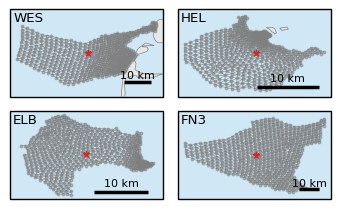

In [ ]:
fig, axs = plt.subplots(2, 2, subplot_kw={"projection": ccrs.PlateCarree()}, figsize=PAPER_NARROW)

axs = axs.flatten()

from pyproj import Geod

def add_scale_bar(ax, length_km=1.0, location=(0.95, 0.05), color="black", linewidth=2.5, fontsize=8):
    """
    Draw a geodesically-accurate scale bar on a lon/lat matplotlib axes.

    ax: matplotlib Axes with data in (lon, lat) -- plain axes or a
        cartopy GeoAxes using PlateCarree (degree-based data coords).
    length_km: length the bar represents, in km.
    location: (x, y) in AXES-relative coords (0-1) for the bar's
        RIGHT/anchor end -- default puts it bottom-right.
    """
    geod = Geod(ellps="WGS84")

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # anchor point in data (lon/lat) coords, from axes-relative location
    anchor_lon = xlim[0] + location[0] * (xlim[1] - xlim[0])
    anchor_lat = ylim[0] + location[1] * (ylim[1] - ylim[0])

    # walk WEST from the anchor by length_km, at this latitude, to get
    # the bar's other endpoint -- geodesically correct regardless of lat
    start_lon, start_lat, _ = geod.fwd(anchor_lon, anchor_lat, 270, length_km * 1000)

    ax.plot(
        [start_lon, anchor_lon], [anchor_lat, anchor_lat],
        color=color, linewidth=linewidth, solid_capstyle="butt",
        transform=ax.transData, zorder=10, clip_on=False,
    )
    ax.text(
        (start_lon + anchor_lon) / 2, anchor_lat + 0.01,
        f"{length_km:g} km",
        ha="center", va="bottom", fontsize=fontsize, zorder=10,
    )

for ip, ax, lb in zip(ips, axs, ["WES", "HEL", "ELB", "FN3"]):

    # nodes
    cnx_lon, cnx_lat = LONLAT_TRANSFORMER.transform(nx.sel(nSCHISM_hgrid_node=partitions[ip][0]).values, ny.sel(nSCHISM_hgrid_node=partitions[ip][0]).values)
    ax.scatter(cnx_lon, cnx_lat, color="C3", marker="*", alpha=1, zorder=4)

    nx_lon, nx_lat = LONLAT_TRANSFORMER.transform(nx.sel(nSCHISM_hgrid_node=partitions[ip][1]).values, ny.sel(nSCHISM_hgrid_node=partitions[ip][1]).values)
    ax.scatter(nx_lon, nx_lat, s=4, color="C7", alpha=0.5, zorder=3)


    # edges
    edge_index = partitions[ip][2]

    edge_src = edge_index[0].numpy()
    edge_dst = edge_index[1].numpy()
    mask = edge_src != edge_dst
    segments = np.stack(
        [np.column_stack([nx_lon[edge_src[mask]], nx_lat[edge_src[mask]]]),
            np.column_stack([nx_lon[edge_dst[mask]], nx_lat[edge_dst[mask]]])],
        axis=1,
    )
    ax.add_collection(
        LineCollection(segments, colors=["C7"], linewidths=0.4, alpha=0.5, zorder=2)
    )

    # generic

    ax.add_feature(cfeature.LAND, facecolor="#e8e8e8", zorder=1)
    ax.add_feature(cfeature.OCEAN, facecolor="#d0e8f5", zorder=0)

    ax.coastlines(resolution="10m", color="C7", linewidth=0.5, zorder=3)

    # label
    ax.text(0.02, 0.98, lb, transform=ax.transAxes, ha="left", va="top")

    ax.set_aspect("equal", adjustable="datalim")
    # extent
    add_scale_bar(ax, length_km=10.0, location=(0.92, 0.08))


fig.tight_layout()

plt.savefig("paper_plots/subgraphs_selected_locations.png", bbox_inches="tight", dpi=200)

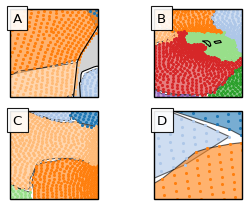

In [ ]:
from matplotlib.patches import Polygon as MplPolygon
import shapely
from shapely.geometry import MultiPoint

fig, axs = plt.subplots(2, 2, figsize=PAPER_NARROW, subplot_kw={"projection": ccrs.PlateCarree()})

axs = axs.flatten()

cmap = plt.colormaps.get_cmap("tab20")

for mp, ax, lb in zip(my_points, axs, ["A", "B", "C", "D"]):

    center_lon, center_lat = mp
    half = 0.125
    lon_min, lon_max = center_lon - half, center_lon + half
    lat_min, lat_max = center_lat - half, center_lat + half

    ax.set_xlim(lon_min, lon_max)
    ax.set_ylim(lat_min, lat_max)
    ax.set_aspect("equal")

    nx_vals, ny_vals = LONLAT_TRANSFORMER.transform(nx.values, ny.values)

    partition_coords = []
    for sg in partitions:
        idx = nx.get_index("nSCHISM_hgrid_node").get_indexer(sg[1])
        partition_coords.append((nx_vals[idx], ny_vals[idx]))

    visible = []
    for lon, lat in partition_coords:
        p_lon_min, p_lon_max = lon.min(), lon.max()
        p_lat_min, p_lat_max = lat.min(), lat.max()
        if p_lon_max >= lon_min and p_lon_min <= lon_max and p_lat_max >= lat_min and p_lat_min <= lat_max:
            visible.append((lon, lat))

    # greedily drop any partition whose CONCAVE hull overlaps an already-kept one
    kept = []
    kept_polys = []
    for lon, lat in visible:
        if len(lon) < 3:
            continue
        poly = shapely.concave_hull(MultiPoint(list(zip(lon, lat))), ratio=0.3)
        kept.append((lon, lat, poly))
        kept_polys.append(poly)

    for i, (lon, lat, poly) in enumerate(kept):
        color = cmap(i % 20)
        ax.add_patch(MplPolygon(np.array(poly.exterior.coords), facecolor=color, edgecolor="black", alpha=0.6))
        ax.scatter(lon, lat, color=color, s=2, zorder=2)

    ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=1)
    ax.coastlines(resolution="10m", linewidth=0.8, zorder=3)

    ax.text(0.03, 0.97, lb, transform=ax.transAxes, ha="left", va="top", bbox=dict(facecolor='white', alpha=0.9))

    #ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
    #gl = ax.gridlines(draw_labels=True, linewidth=0, color="none")
    #gl.top_labels = False
    #gl.right_labels = False
    #gl.xlabel_style = {"size": 7}
    #gl.ylabel_style = {"size": 7}
    
plt.tight_layout()

plt.savefig("subgraph_partitions.png", dpi=200)

plt.show()

In [ ]:
my_points, xt

([(8.222, 54.917), (7.868, 54.16), (8.1105, 53.997), (7.15, 55.2)],
 [7, 9, 53.5, 55.5])

914


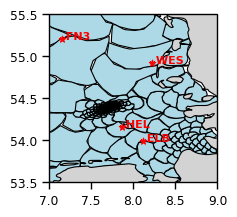

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=PAPER_NARROW, subplot_kw={"projection": ccrs.PlateCarree()})

cmap = plt.colormaps.get_cmap("tab20")

center_lon = 8
center_lat = 54.5
half = 1.0

lon_min, lon_max = center_lon - half, center_lon + half
lat_min, lat_max = center_lat - half, center_lat + half

ax.set_xlim(lon_min, lon_max)
ax.set_ylim(lat_min, lat_max)
ax.set_aspect("equal")

nx_vals, ny_vals = LONLAT_TRANSFORMER.transform(nx.values, ny.values)

partition_coords = []
for sg in partitions:
    idx = nx.get_index("nSCHISM_hgrid_node").get_indexer(sg[1])
    partition_coords.append((nx_vals[idx], ny_vals[idx]))

visible = []
for lon, lat in partition_coords:
    p_lon_min, p_lon_max = lon.min(), lon.max()
    p_lat_min, p_lat_max = lat.min(), lat.max()
    if p_lon_max >= lon_min and p_lon_min <= lon_max and p_lat_max >= lat_min and p_lat_min <= lat_max:
        visible.append((lon, lat))

# greedily drop any partition whose CONCAVE hull overlaps an already-kept one
kept = []
kept_polys = []
for lon, lat in visible:
    if len(lon) < 3:
        continue

    if np.ptp(lat) < 0.001:
        continue
        
    poly = shapely.concave_hull(MultiPoint(list(zip(lon, lat))), ratio=0.3)
    kept.append((lon, lat, poly))
    kept_polys.append(poly)

print(len(kept_polys))

for i, (lon, lat, poly) in enumerate(kept):
    color = cmap(i % 20)
    ax.add_patch(MplPolygon(np.array(poly.exterior.coords), facecolor="lightblue", edgecolor="black", alpha=1.0))
    #ax.scatter(lon, lat, color=color, s=2, zorder=2)

ax.add_feature(cfeature.LAND, facecolor="lightgray", zorder=1)
ax.coastlines(resolution="10m", linewidth=0.8, zorder=3)

for mp, b in zip(my_points, [" WES", " HEL", " ELB", " FN3"]):
    ax.scatter(mp[0], mp[1], color="red", marker="*", zorder=4)
    ax.text(mp[0], mp[1], b, fontsize=8, fontweight="bold", color="red")

ax.set_xticks([7, 7.5, 8, 8.5, 9])
ax.set_yticks([53.5, 54.0, 54.5, 55.0, 55.5])

#gl = ax.gridlines(draw_labels=True, linewidth=0, color="none")
#gl.top_labels = False
#gl.right_labels = False
#gl.xlabel_style = {"size": 7}
#gl.ylabel_style = {"size": 7}
    
#plt.tight_layout()

#plt.savefig("subgraph_partitions.png", dpi=200)

plt.show()